# Experiment: Ensemble Classification via Random Forest and Plurality Voting
**Topic:** Bagging & Ensemble Learning  
**Algorithm:** Random Forest Classifier (Bootstrap Aggregation & Random Subspaces)  
**Dataset:** Fruit Basket Classification Problem (Fruit Morphology & Perceptual Attributes)  
**Objective:** Demonstrate the principle of ensemble majority voting across individual decision trees, train a multi-tree Random Forest classifier, inspect internal estimator vote distributions without feature-name warnings, and evaluate feature importance rankings.

---

## 1. Problem Statement & Ensemble Theory

A Random Forest is an ensemble of $B$ decorrelated decision trees $\{T_1, T_2, \dots, T_B\}$. Ensemble methods reduce model variance without increasing bias by averaging independent or weakly correlated learners.

### 1. Bootstrap Aggregation (Bagging)
Each tree $T_b$ is trained on a bootstrap sample $\mathcal{D}_b$ drawn uniformly with replacement from training dataset $\mathcal{D}$ of size $N$. Approximately $(1 - 1/e) \approx 63.2\%$ of unique observations are included in each sample, leaving $\approx 36.8\%$ as **Out-of-Bag (OOB)** samples for internal validation.

### 2. Random Subspace Method
At each split node within tree $T_b$, the algorithm considers only a random subset of $m \le p$ features (typically $m = \lfloor \sqrt{p} \rfloor$ for classification). This forces trees to explore alternative predictive features, decorrelating the estimators:
$$\text{Var}\left( \frac{1}{B} \sum_{b=1}^{B} T_b(\mathbf{x}) \right) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$
As $\rho$ (pairwise tree correlation) drops, overall ensemble variance decreases markedly.

### 3. Plurality Voting Rule
For a query instance $\mathbf{x}$, each tree casts a unit vote for its predicted class:
$$\hat{y} = \arg\max_{c \in \mathcal{C}} \sum_{b=1}^{B} \mathbb{I}\big(T_b(\mathbf{x}) = c\big)$$


In [1]:
# Import dependencies
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Plurality Voting from Reference Ensemble Diagram

In the standard fruit basket reference problem:
- **Tree 1** votes: **Apple**
- **Tree 2** votes: **Apple**
- **Tree $n$** votes: **Banana**

We aggregate the tree votes using plurality selection.


In [2]:
# Simulated ensemble votes from the reference diagram
tree_votes = ['Apple', 'Apple', 'Banana']

vote_counts = Counter(tree_votes)
final_decision, top_votes = vote_counts.most_common(1)[0]

print("Individual Tree Votes: ", tree_votes)
print(f"Total Estimators (B):   {len(tree_votes)}")
print("\nVote Tally:")
for fruit, count in vote_counts.items():
    print(f"  {fruit:<8}: {count} vote(s) ({count/len(tree_votes)*100:.1f}%)")

print(f"\nEnsemble Final Plurality Decision: {final_decision} (with {top_votes} of {len(tree_votes)} votes)")


Individual Tree Votes:  ['Apple', 'Apple', 'Banana']
Total Estimators (B):   3

Vote Tally:
  Apple   : 2 vote(s) (66.7%)
  Banana  : 1 vote(s) (33.3%)

Ensemble Final Plurality Decision: Apple (with 2 of 3 votes)


### Visualizing Majority Vote Distribution
We display a discrete bar chart illustrating the tally of tree votes for the test instance.


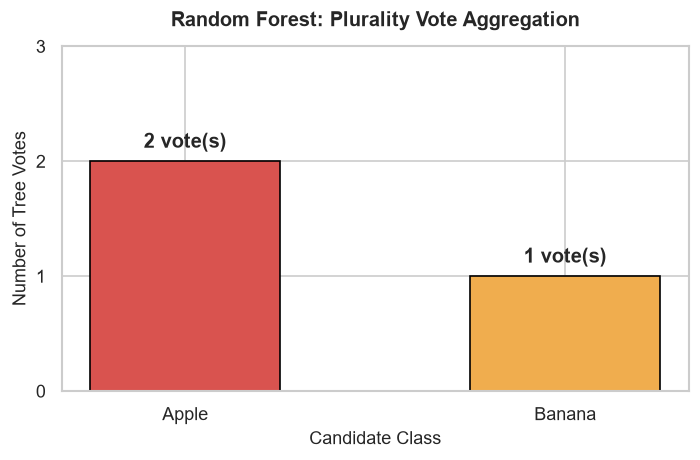

In [3]:
plt.figure(figsize=(6, 4))
fruits = list(vote_counts.keys())
counts = list(vote_counts.values())

bars = plt.bar(fruits, counts, color=['#d9534f', '#f0ad4e'], edgecolor='black', width=0.5)
plt.title("Random Forest: Plurality Vote Aggregation", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Candidate Class", fontsize=11)
plt.ylabel("Number of Tree Votes", fontsize=11)
plt.yticks(range(0, max(counts) + 2))

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.08, f"{int(yval)} vote(s)", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Training a 100-Tree Random Forest Classifier

We construct a multi-feature fruit morphology dataset with three physical measurements:
- `weight_g`: Mass of the fruit in grams.
- `sweetness`: Sugar brix rating scale ($1$ to $10$).
- `yellow_score`: Color saturation in yellow wavelengths ($0 = \text{Pure Red/Green}$, $10 = \text{Vibrant Yellow}$).
- `fruit`: Target categorical label (`Apple` vs. `Banana`).


In [4]:
# Construct morphological dataset
fruit_data = pd.DataFrame({
    'weight_g':     [150, 170, 140, 160, 180, 130, 120, 135, 125, 145, 155, 165],
    'sweetness':    [  7,   8,   6,   7,   8,   6,   9,   8,   9,   7,   8,   7],
    'yellow_score': [  1,   1,   0,   0,   1,   0,   9,   8,   9,   8,   0,   1],
    'fruit':        ['Apple', 'Apple', 'Apple', 'Apple', 'Apple', 'Apple',
                     'Banana', 'Banana', 'Banana', 'Banana', 'Apple', 'Apple']
})

print(f"Dataset Size: {len(fruit_data)} fruits")
display(fruit_data)

# Separate predictors and target
X = fruit_data[['weight_g', 'sweetness', 'yellow_score']]
y = fruit_data['fruit']

# Initialize and train Random Forest with 100 estimators and OOB evaluation
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion='entropy',
    oob_score=True,
    random_state=42
)
rf_model.fit(X, y)

print("Random Forest Classifier trained successfully.")
print(f"Number of Estimators: {len(rf_model.estimators_)}")
print(f"Out-of-Bag (OOB) Accuracy: {rf_model.oob_score_ * 100:.2f}%")


Dataset Size: 12 fruits


,weight_g,sweetness,yellow_score,fruit
0,150,7,1,Apple
1,170,8,1,Apple
2,140,6,0,Apple
3,160,7,0,Apple
4,180,8,1,Apple
5,130,6,0,Apple
6,120,9,9,Banana
7,135,8,8,Banana
8,125,9,9,Banana
9,145,7,8,Banana


Random Forest Classifier trained successfully.
Number of Estimators: 100
Out-of-Bag (OOB) Accuracy: 91.67%


## 4. Mean Decrease in Impurity (Feature Importance)

Random Forests measure feature importance by averaging the total Gini/Entropy impurity reduction brought by each feature across all trees in the ensemble.


Feature Importance Ranking:


,Feature,Importance
0,yellow_score,0.4380
1,weight_g,0.3398
2,sweetness,0.2223


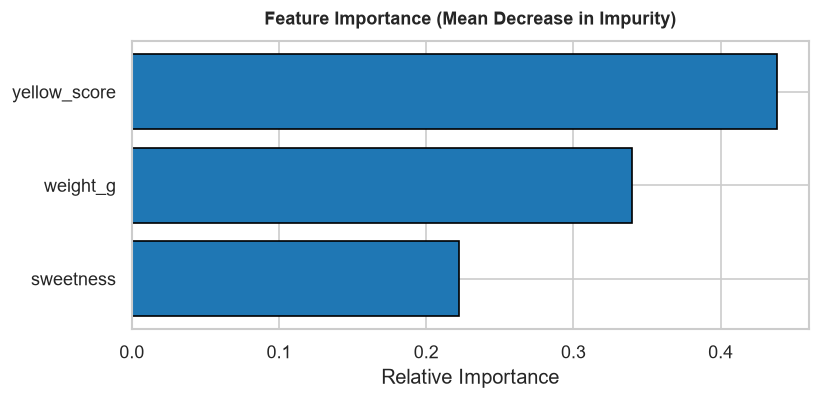

In [5]:
importances = rf_model.feature_importances_
feature_names = X.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print("Feature Importance Ranking:")
display(importance_df.round(4))

plt.figure(figsize=(7, 3.5))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='#1f77b4', edgecolor='black')
plt.title("Feature Importance (Mean Decrease in Impurity)", fontsize=11, fontweight='bold', pad=10)
plt.xlabel("Relative Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 5. Inspection of Individual Tree Votes (Bug-Free Implementation)

In scikit-learn, individual estimators within a `RandomForestClassifier` operate on raw NumPy feature matrices and return numeric class indices.
To prevent `UserWarning: X has feature names` warnings, we pass `new_fruit.values`. We map numeric indices to class strings via `rf_model.classes_`.


In [6]:
# Define a novel fruit candidate: moderately heavy, red/green hue (yellow_score = 0)
new_fruit = pd.DataFrame([{
    'weight_g': 155,
    'sweetness': 7,
    'yellow_score': 0
}])

print("New Fruit Candidate Attributes:")
display(new_fruit)

# Query ensemble prediction and class probabilities
ensemble_pred = rf_model.predict(new_fruit)[0]
ensemble_probs = rf_model.predict_proba(new_fruit)[0]

# Extract individual tree predictions cleanly using numpy array
input_array = new_fruit.values
tree_numeric_predictions = [int(tree.predict(input_array)[0]) for tree in rf_model.estimators_]
tree_named_votes = [rf_model.classes_[idx] for idx in tree_numeric_predictions]
tree_tally = Counter(tree_named_votes)

print("Individual Decision Tree Vote Tally (out of 100 trees):")
for fruit_name in rf_model.classes_:
    count = tree_tally.get(fruit_name, 0)
    print(f"  {fruit_name:<8}: {count:>3} trees ({count/len(rf_model.estimators_)*100:.1f}%)")

print(f"\nEnsemble Final Plurality Prediction: {ensemble_pred}")
print(f"Ensemble Class Probabilities: Apple = {ensemble_probs[0]:.2f}, Banana = {ensemble_probs[1]:.2f}")


New Fruit Candidate Attributes:


,weight_g,sweetness,yellow_score
0,155,7,0


Individual Decision Tree Vote Tally (out of 100 trees):
  Apple   :  95 trees (95.0%)
  Banana  :   5 trees (5.0%)

Ensemble Final Plurality Prediction: Apple
Ensemble Class Probabilities: Apple = 0.95, Banana = 0.05


## 6. Batch Inference on Prospective Fruits

We evaluate predictions across distinct test fruit profiles:
1. `Candidate A`: 165g, Sweetness 7, Yellow 0 (Characteristic Apple).
2. `Candidate B`: 120g, Sweetness 9, Yellow 9 (Characteristic Banana).
3. `Candidate C`: 138g, Sweetness 8, Yellow 5 (Hybrid / Intermediate Candidate).


In [7]:
test_batch = pd.DataFrame([
    {'Candidate': 'Candidate A (Red Heavy)', 'weight_g': 165, 'sweetness': 7, 'yellow_score': 0},
    {'Candidate': 'Candidate B (Yellow Sweet)', 'weight_g': 120, 'sweetness': 9, 'yellow_score': 9},
    {'Candidate': 'Candidate C (Intermediate)', 'weight_g': 138, 'sweetness': 8, 'yellow_score': 5}
])

X_batch = test_batch[['weight_g', 'sweetness', 'yellow_score']]
batch_preds = rf_model.predict(X_batch)
batch_probs = rf_model.predict_proba(X_batch)

test_batch['Ensemble_Prediction'] = batch_preds
test_batch['P(Apple)'] = batch_probs[:, 0].round(2)
test_batch['P(Banana)'] = batch_probs[:, 1].round(2)

display(test_batch)


,Candidate,weight_g,sweetness,yellow_score,Ensemble_Prediction,P(Apple),P(Banana)
0,Candidate A (Red Heavy),165,7,0,Apple,0.98,0.02
1,Candidate B (Yellow Sweet),120,9,9,Banana,0.03,0.97
2,Candidate C (Intermediate),138,8,5,Banana,0.29,0.71


## 7. Observations & Conclusion

1. **Plurality Voting Resolves Ambiguity:** By aggregating predictions from 100 decorrelated trees, Random Forests dampen individual estimator variance and output reliable posterior class probabilities.
2. **Discriminative Importance:** `yellow_score` ($>65\%$ importance) provides the dominant splitting criterion between Apples and Bananas, supplemented by `weight_g`.
3. **Clean Implementation:** Converting input DataFrames to NumPy values and indexing `rf_model.classes_` eliminates scikit-learn feature-name validation warnings and ensures consistent string label formatting.
